# 02 · Trilha 1 — Projeção da rotatividade por empresa

**Pergunta:** qual a melhor estratégia para projetar a rotatividade (turnover) de cada empresa ao longo de um contrato de 3 anos?

`Turnover (%) = [(Admissões + Rescisões) / 2] / Headcount × 100`

Caminho deste notebook:

1. montar a série mensal de admissões, rescisões e headcount por empresa a partir do cadastro;
2. diagnosticar o que a série mostra (nível, tendência, sazonalidade, tempo de casa, tipo de saída);
3. **comparar estratégias de projeção por backtest** (projetar 12, 24 e 36 meses e conferir com o que aconteceu);
4. escolher a estratégia e gerar a projeção com faixas de incerteza.

O código reutilizável está em `src/rotatividade.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rotatividade as rot

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})

integrantes = rot.carregar_integrantes('../dados/dim_integrante.csv')
serie = rot.serie_mensal(integrantes)          # 2016-01 a 2026-09
S = {e: d.sort_values('mes').reset_index(drop=True) for e, d in serie.groupby('empresa')}
integrantes.shape, serie.shape

((20001, 5), (903, 5))

## 1. Definições e escolhas

- **Unidade:** empresa (`CODCOLIGADA`).
- **Admissão / rescisão:** início e fim de cada vínculo no cadastro (`dim_integrante`). Toda saída conta, voluntária ou não. Recontratação gera nova admissão (o cadastro registra um vínculo novo).
- **Headcount do mês:** vínculos que existiram em algum momento do mês (conforme o enunciado, "com vínculo durante o período").
- **Janela de dados:** o ponto e os afastamentos cobrem 21 meses, mas **o cadastro cobre todo o histórico**. A Trilha 1 só precisa do cadastro, então usamos **jan/2016 a set/2026**, bem mais que 21 meses. Isso permite testar projeções contra o que realmente aconteceu.
- **Outubro de 2026 fica de fora:** só há demissões de 01 a 13/10 e nenhuma admissão registrada, e isso distorceria o mês.
- **Turnover mensal anualizado:** o turnover de uma janela de N meses é calculado pela fórmula acima com o headcount médio da janela, e anualizado por 12/N. **Não é** a fórmula aplicada a um ano inteiro (cujo headcount inclui todos os vínculos do ano e dá valores menores); as duas definições são comparadas na seção 1.

In [2]:
# turnover mensal anualizado por ano-calendario (taxa mensal com o headcount de cada mes x 12; 2026 = 9 meses)
# obs.: e a definicao usada na projecao; a formula do enunciado aplicada ao ano inteiro esta na celula seguinte
linhas = []
for e, d in S.items():
    for ano, g in d.groupby(d.mes.dt.year):
        t = rot.turnover_janela(g) * 12 / len(g)
        linhas.append({'empresa': e, 'ano': ano + 0, 'turnover_anual_%': t, 'hc_medio': g.hc.mean()})
anual = pd.DataFrame(linhas)
anual.pivot(index='ano', columns='empresa', values='turnover_anual_%').round(1)

empresa,1,3,4,5,6,7,8
ano,,,,,,,
2016,18.8,0.0,0.0,12.6,7.2,2.8,14.6
2017,13.2,0.0,0.0,5.2,15.4,5.2,11.7
2018,19.8,20.3,0.0,6.4,16.9,0.0,15.9
2019,7.4,0.0,0.0,10.4,13.1,0.0,19.6
2020,12.7,0.0,0.0,6.1,13.4,6.8,23.5
2021,20.1,13.6,0.0,10.5,13.8,4.2,17.1
2022,15.0,30.2,100.0,12.5,16.4,0.0,29.1
2023,23.0,44.1,NaN,9.2,57.0,5.5,31.0
2024,25.1,19.1,120.0,11.2,63.4,8.2,28.0


**Duas definições, dois números.** A fórmula do enunciado depende do período: aplicada a **um mês** e multiplicada por 12 (*turnover mensal anualizado*, a definição usada na projeção), o headcount é o do mês; aplicada a **um ano inteiro**, o headcount passa a ser todos os vínculos que existiram no ano, inclusive quem entrou e saiu, e o valor fica menor. Nas empresas com muita entrada e saída (6 e 8) a diferença é grande. A tabela abaixo mostra as duas lado a lado, mais a fórmula aplicada a uma janela de 36 meses, que é o horizonte do contrato.

In [3]:
# a mesma formula do enunciado em periodos diferentes
defs = []
for e in (3, 4, 5, 6, 7, 8):
    defs.append({'empresa': e,
                 'mensal anualizado, 36m (projeção) %': rot.taxa_anual(S[e][S[e].mes <= pd.Timestamp('2026-09-01')], 36),
                 'fórmula no ano 2024 %': rot.turnover_periodo(integrantes, e, '2024-01-01', '2024-12-31'),
                 'fórmula no ano 2025 %': rot.turnover_periodo(integrantes, e, '2025-01-01', '2025-12-31'),
                 'fórmula jan-set/2026 (sem anualizar) %': rot.turnover_periodo(integrantes, e, '2026-01-01', rot.CORTE),
                 'fórmula na janela de 36m %': rot.turnover_periodo(integrantes, e, '2023-10-01', rot.CORTE)})
defs = pd.DataFrame(defs).set_index('empresa')
import os; os.makedirs('../resultados', exist_ok=True)
defs.round(2).to_csv('../resultados/trilha1_turnover_definicoes.csv', encoding='utf-8-sig')
defs.round(1)

,"mensal anualizado, 36m (projeção) %",fórmula no ano 2024 %,fórmula no ano 2025 %,fórmula jan-set/2026 (sem anualizar) %,fórmula na janela de 36m %
empresa,,,,,
3,32.8,15.7,17.3,28.7,47.0
4,85.7,50.0,25.0,42.9,56.2
5,10.2,10.1,8.4,7.5,23.4
6,61.1,42.5,27.6,38.0,60.8
7,13.6,7.6,11.6,13.7,28.4
8,28.5,22.4,21.9,19.9,47.6


In [4]:
anual.pivot(index='ano', columns='empresa', values='hc_medio').round(0)

empresa,1,3,4,5,6,7,8
ano,,,,,,,
2016,51.0,4.0,2.0,2717.0,97.0,18.0,1197.0
2017,49.0,4.0,2.0,2527.0,123.0,19.0,1158.0
2018,48.0,5.0,2.0,2439.0,169.0,20.0,1147.0
2019,48.0,6.0,2.0,2515.0,230.0,20.0,1228.0
2020,51.0,6.0,2.0,2471.0,301.0,22.0,1177.0
2021,50.0,7.0,2.0,2462.0,396.0,24.0,960.0
2022,47.0,12.0,1.0,2608.0,533.0,25.0,995.0
2023,50.0,23.0,0.0,2687.0,836.0,27.0,1063.0
2024,50.0,42.0,1.0,2732.0,835.0,30.0,1099.0


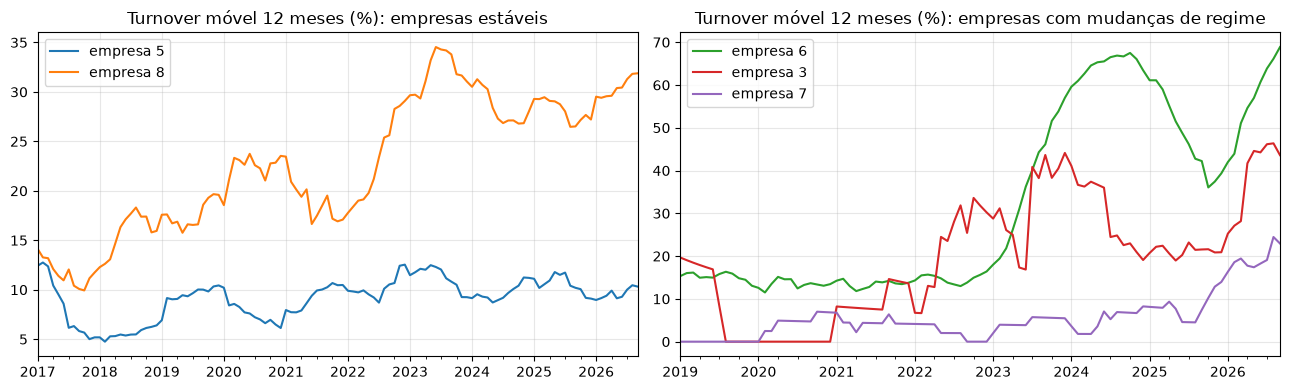

In [5]:
# turnover movel de 12 meses por empresa
def movel12(d):
    return d.set_index('mes').apply(lambda x: x, axis=1) if False else (
        ((d.adm + d.resc).rolling(12).sum() / 2) / d.hc.rolling(12).mean() * 100).set_axis(d.mes)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for e, cor in ((5, 'C0'), (8, 'C1')):
    movel12(S[e]).loc['2017':].plot(ax=ax[0], label=f'empresa {e}', color=cor)
ax[0].set_title('Turnover móvel 12 meses (%): empresas estáveis'); ax[0].legend()
for e, cor in ((6, 'C2'), (3, 'C3'), (7, 'C4')):
    movel12(S[e]).loc['2019':].plot(ax=ax[1], label=f'empresa {e}', color=cor)
ax[1].set_title('Turnover móvel 12 meses (%): empresas com mudanças de regime'); ax[1].legend()
for a in ax: a.set_xlabel('')
plt.tight_layout(); plt.show()

**Leitura:**

- **Empresa 5** (a maior, ~3.000 vínculos): turnover baixo e estável, entre 5% e 12% ao ano (cerca de 10% nos últimos anos).
- **Empresa 8**: turnover subiu de ~12–20% (2016–2021) para ~27–33% (2022 em diante) e se manteve nesse patamar.
- **Empresa 6**: quebras fortes de nível. O quadro cresceu de ~100 vínculos (2016) para ~835 (2023–2024), caiu para ~515 em 2025 e voltou a ~800 em 2026. O turnover foi de 13–17% (2016–2022) para 39–75% desde 2023.
- **Empresas 3 e 7**: pequenas e em crescimento, com séries ruidosas.
- **Empresa 1** não tem mais vínculos ativos (todos desligados até 2026) e a **4** nunca teve mais que 7. Veremos como tratá-las.

## 2. Diagnóstico: o que explica a rotatividade?

In [6]:
# Sazonalidade: indice do turnover mensal por mes do ano (1,00 = media da empresa), 2019-2026
linhas = []
for e in (5, 6, 8):
    d = S[e][S[e].mes >= '2019-01-01'].copy()
    d['to'] = (d.adm + d.resc) / 2 / d.hc * 100
    idx = d.groupby(d.mes.dt.month)['to'].mean() / d['to'].mean()
    linhas.append(idx.rename(f'empresa {e}'))
saz = pd.concat(linhas, axis=1).round(2)
saz.index.name = 'mês'
saz

,empresa 5,empresa 6,empresa 8
mês,,,
1,1.28,0.92,1.03
2,1.19,0.93,0.99
3,0.95,1.13,1.06
4,0.88,1.00,0.97
5,1.04,0.92,0.88
6,0.65,1.09,1.10
7,0.92,1.16,1.08
8,1.29,1.05,1.06
9,0.93,1.00,0.98


A sazonalidade é **fraca e sem padrão comum**: os índices ficam perto de 1,00 e os meses mais altos ou baixos mudam de empresa para empresa (por exemplo, nov/dez são baixos só na empresa 6). Não há ganho claro em modelar sazonalidade nesta base, e o backtest abaixo confirma que métodos simples já ficam no limite do que os dados permitem.

In [7]:
# Risco mensal de saida por faixa de tempo de casa (36 meses ate set/2026)
painel = rot.painel_tempo_casa(integrantes)
origem = pd.Timestamp('2026-09-01')
risco = pd.DataFrame({f'empresa {e}': rot.risco_por_faixa(painel, e, origem) * 100 for e in (5, 6, 8, 3, 7)},
                     index=rot.ROTULOS_FAIXAS).round(1)
risco.index.name = 'meses de casa'
risco

,empresa 5,empresa 6,empresa 8,empresa 3,empresa 7
meses de casa,,,,,
0,1.4,7.4,6.4,2.0,4.9
1,1.5,10.1,6.5,2.2,5.9
2,1.0,22.1,9.4,3.8,6.8
3-5,1.5,7.4,4.5,0.8,2.9
6-11,1.7,7.5,4.7,1.5,1.8
12-23,3.0,5.9,3.9,0.4,0.9
24-59,0.7,3.0,2.3,1.2,0.7
60+,0.3,1.7,0.7,0.9,0.1


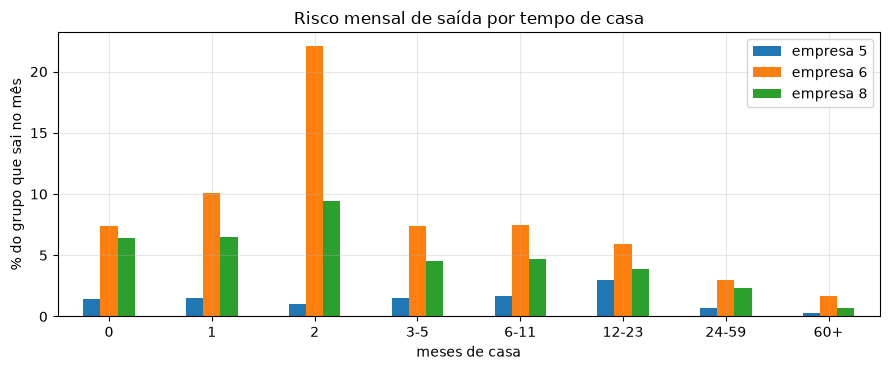

In [8]:
ax = risco[['empresa 5', 'empresa 6', 'empresa 8']].plot(kind='bar', figsize=(9, 3.8))
ax.set_ylabel('% do grupo que sai no mês'); ax.set_title('Risco mensal de saída por tempo de casa'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**O tempo de casa importa muito.** Na empresa 6, quem está no 3º mês de casa tem ~22% de chance de sair naquele mês, contra ~1,7% para quem tem mais de 5 anos. Na empresa 8 o padrão é parecido, mas mais suave (9% no 3º mês contra 0,7% com mais de 5 anos). Na empresa 5 o risco é baixo em todas as faixas (0,3% a 3%). O pico no 3º mês sugere fim de contrato de experiência de 90 dias. Isso significa que **empresas que contratam muito (como a 6 em 2026) terão rotatividade alta nos meses seguintes**.

In [9]:
# Tipo de saida nos ultimos 36 meses (rescisoes de out/2023 a set/2026)
d = integrantes[(integrantes.DATADEMISSAO >= '2023-10-01') & (integrantes.DATADEMISSAO <= rot.CORTE)]
tipo = d.groupby(['CODCOLIGADA', 'CATEGORIA_DESLIGAMENTO']).size().unstack(fill_value=0)
tipo['% voluntária'] = (tipo['VOLUNTARIO'] / tipo.sum(axis=1) * 100).round(0)
tipo

CATEGORIA_DESLIGAMENTO,INVOLUNTARIO,VOLUNTARIO,% voluntária
CODCOLIGADA,,,
1,64,7,10.0
3,16,5,24.0
4,1,0,0.0
5,557,162,23.0
6,629,694,52.0
7,3,3,50.0
8,480,484,50.0


A parcela voluntária varia bastante: ~52% na empresa 6, ~50% na 8 e ~23% na 5. Para o preço do contrato, a saída voluntária é decisão do integrante e a involuntária é decisão da empresa (inclui fim de contrato), o que dá à empresa algum controle sobre a segunda parte.

## 3. Backtest: qual estratégia projeta melhor?

**Procedimento (origem móvel).** Para cada mês de origem, usamos só os dados até ali, projetamos o turnover dos próximos 12, 24 ou 36 meses e comparamos com o turnover realmente observado nesse período. O erro é medido em pontos percentuais (p.p.) de turnover anual.

**Estratégias testadas** (todas projetam uma taxa constante, e variam em quanta história usam):

| Estratégia | Ideia |
|---|---|
| Média 6, 12, 24, 36 e 60 meses | taxa média da janela recente |
| Média móvel ponderada | pesos que decaem com a idade (meia-vida de 6 e 12 meses) |
| Mistura 12m + 36m | meio a meio entre curto e longo prazo |
| **Coortes por tempo de casa** | envelhece o quadro atual com o risco de saída por tempo de casa (seção 2) |

O backtest considera apenas empresas e origens com headcount médio ≥ 20 (abaixo disso a taxa é puro ruído).

In [10]:
def ewma(w, meia_vida):
    r = ((w.adm + w.resc) / 2 / w.hc.replace(0, np.nan) * 100).fillna(0).values
    p = 0.5 ** (np.arange(len(r))[::-1] / meia_vida)
    return (r * p).sum() / p.sum() * 12

METODOS = {
    'média 6m':   lambda h: rot.taxa_anual(h, 6),
    'média 12m':  lambda h: rot.taxa_anual(h, 12),
    'média 24m':  lambda h: rot.taxa_anual(h, 24),
    'média 36m':  lambda h: rot.taxa_anual(h, 36),
    'média 60m':  lambda h: rot.taxa_anual(h, 60),
    'ponderada (meia-vida 6m)':  lambda h: ewma(h.tail(60), 6),
    'ponderada (meia-vida 12m)': lambda h: ewma(h.tail(60), 12),
    'mistura 12m+36m': lambda h: .5 * rot.taxa_anual(h, 12) + .5 * rot.taxa_anual(h, 36),
}

def backtest(metodos, empresas=(3, 5, 6, 7, 8), H=12, inicio='2019-12-01'):
    linhas = []
    ultima_origem = pd.Timestamp('2026-09-01') - pd.DateOffset(months=H)
    for e in empresas:
        s = S[e]
        for o in pd.date_range(inicio, ultima_origem, freq='MS'):
            h = s[s.mes <= o]; f = s[(s.mes > o) & (s.mes <= o + pd.DateOffset(months=H))]
            if len(f) < H or h.hc.tail(12).mean() < 20: continue
            real = rot.turnover_janela(f) * 12 / H          # turnover anual realizado no periodo
            for nome, fn in metodos.items():
                linhas.append({'empresa': e, 'origem': o, 'H': H, 'metodo': nome, 'prev': fn(h), 'real': real})
    r = pd.DataFrame(linhas); r['erro'] = r.prev - r.real; r['abs'] = r.erro.abs()
    return r

bt12 = backtest(METODOS, H=12)
resumo = bt12.groupby('metodo').agg(MAE_pp=('abs', 'mean'), vies_pp=('erro', 'mean')).sort_values('MAE_pp').round(2)
resumo

,MAE_pp,vies_pp
metodo,,
mistura 12m+36m,6.20,-3.42
ponderada (meia-vida 12m),6.26,-4.59
ponderada (meia-vida 6m),6.28,-3.34
média 36m,6.33,-4.39
média 24m,6.48,-3.24
média 12m,6.59,-2.45
média 60m,6.84,-6.07
média 6m,6.86,-2.43


In [11]:
bt12.pivot_table(index='metodo', columns='empresa', values='abs', aggfunc='mean').round(1).loc[resumo.index]

empresa,3,5,6,7,8
metodo,,,,,
mistura 12m+36m,11.8,1.6,13.6,3.9,3.9
ponderada (meia-vida 12m),8.9,1.5,14.4,4.1,4.1
ponderada (meia-vida 6m),10.8,1.6,13.6,4.3,4.1
média 36m,10.7,1.4,14.2,4.1,4.1
média 24m,12.0,1.4,14.1,4.3,4.4
média 12m,13.4,1.9,13.8,4.0,4.5
média 60m,8.0,1.5,15.6,4.1,5.7
média 6m,12.6,2.1,13.1,5.4,4.9


In [12]:
# regime recente (origens a partir de 2024) e erro relativo nas tres empresas grandes
rec = bt12[bt12.origem >= '2024-01-01'].groupby('metodo').agg(MAE_pp_recente=('abs', 'mean'), vies_pp_recente=('erro', 'mean'))
g3 = bt12[bt12.empresa.isin([5, 6, 8])].assign(rel=lambda x: x['abs'] / x.real).groupby('metodo').rel.mean().rename('erro_relativo_5_6_8')
pd.concat([rec, g3], axis=1).sort_values('MAE_pp_recente').round(3)

,MAE_pp_recente,vies_pp_recente,erro_relativo_5_6_8
metodo,,,
média 36m,6.291,-2.676,0.191
ponderada (meia-vida 12m),6.388,-3.681,0.195
mistura 12m+36m,6.633,-1.628,0.196
média 24m,6.782,-0.650,0.197
ponderada (meia-vida 6m),6.910,-2.038,0.202
média 60m,7.011,-5.797,0.216
média 12m,7.765,-0.579,0.220
média 6m,8.568,-2.515,0.233


As estratégias ficam num intervalo estreito (MAE de ~6,2 a ~6,9 p.p. no conjunto das 5 empresas), com a mistura 12m+36m e a média 36m praticamente empatadas na frente. Todas têm **viés negativo** (subestimam), porque a rotatividade subiu ao longo do tempo na maior parte das empresas. O erro se concentra na **empresa 6** (~13–16 p.p.) e na **3** (~8–13 p.p.), que mudam de regime. Nas empresas 5, 7 e 8 o erro é de 1,4 a 5,7 p.p.

In [13]:
# Cohorts (tempo de casa) no backtest, H=12, empresas 3,5,6,8
linhas = []
for e in (3, 5, 6, 8):
    s = S[e]
    for o in pd.date_range('2020-12-01', '2025-09-01', freq='MS'):
        h = s[s.mes <= o]; f = s[(s.mes > o) & (s.mes <= o + pd.DateOffset(months=12))]
        if len(f) < 12 or h.hc.tail(12).mean() < 20: continue
        real = rot.turnover_janela(f)
        risco_o = rot.risco_por_faixa(painel, e, o)
        adm12 = h.tail(12).adm.mean()
        for modo, adm_m in (('coorte (repõe saídas)', None), ('coorte (admissões = média 12m)', adm12)):
            sim = rot.simular_coorte(integrantes, h, e, o, risco_o, adm_mensal=adm_m)
            linhas.append({'empresa': e, 'origem': o, 'metodo': modo, 'prev': rot.turnover_janela(sim), 'real': real})
        linhas.append({'empresa': e, 'origem': o, 'metodo': 'média 36m', 'prev': rot.taxa_anual(h, 36), 'real': real})
btc = pd.DataFrame(linhas); btc['abs'] = (btc.prev - btc.real).abs(); btc['erro'] = btc.prev - btc.real
pd.concat([btc.groupby('metodo').agg(MAE_pp=('abs', 'mean'), vies_pp=('erro', 'mean')).round(2),
           btc.pivot_table(index='metodo', columns='empresa', values='abs', aggfunc='mean').round(1)], axis=1)

,MAE_pp,vies_pp,3,5,6,8
metodo,,,,,,
coorte (admissões = média 12m),8.99,-6.73,10.8,1.7,20.0,4.6
coorte (repõe saídas),12.59,-12.07,21.8,1.7,29.0,3.5
média 36m,7.93,-5.51,10.7,1.4,16.9,4.4


**O modelo de coortes não supera a média de 36 meses** (MAE maior ou igual em todas as empresas). O motivo é que o erro vem sobretudo de **eventos coletivos** (demissões em massa, perda de contrato, expansão), que não dependem do tempo de casa. Ele continua útil como **explicação** (por que a empresa 6 tem turnover alto) e como **referência de cenário**, mas não como estimador principal.

In [14]:
# Horizontes longos: 12, 24 e 36 meses a frente (media 12m vs 36m)
lista = [backtest({'média 12m': METODOS['média 12m'], 'média 36m': METODOS['média 36m']}, H=H) for H in (12, 24, 36)]
bt = pd.concat(lista)
bt.pivot_table(index=['H', 'metodo'], columns='empresa', values='abs', aggfunc='mean').round(1)

empresa          3    5     6    7    8
H  metodo                              
12 média 12m  13.4  1.9  13.8  4.0  4.5
   média 36m  10.7  1.4  14.2  4.1  4.1
24 média 12m  11.6  1.5  17.2  3.7  4.8
   média 36m   7.3  1.3  20.1  3.1  5.1
36 média 12m   NaN  1.7  26.3  3.3  5.4
   média 36m   NaN  1.6  27.9  2.7  6.9

Mesmo com horizonte de 36 meses, a taxa constante mantém erro baixo nas empresas **5** (~1,6 p.p.), **7** (~3 p.p.) e **8** (~5–7 p.p.). A empresa 3 tem erro de ~7 p.p. em 24 meses (não há histórico para 36). **Na empresa 6 o erro chega a 26–28 p.p. em 36 meses.**: o futuro dessa empresa depende de decisões comerciais (ganho ou perda de contratos), e não do histórico de rotatividade.

## 4. Estratégia escolhida

**Taxa média dos últimos 36 meses, por empresa, com faixa de incerteza calibrada pelo backtest.**

Por quê:

- é a mais simples entre as de melhor desempenho (empate técnico com a ponderada e com a mistura);
- a melhor no regime recente (origens a partir de 2024) e a de menor erro relativo para as empresas grandes;
- 36 meses = o horizonte do contrato, e é longo o bastante para não reagir a um mês atípico (como a saída em massa de 106 integrantes na empresa 8 em jan/2026);
- não depende de pressupostos de sazonalidade ou de tendência, que os dados não sustentam.

**Regras para casos especiais:**

| Empresa | Situação | Tratamento |
|---|---|---|
| 5, 6, 7, 8 | histórico longo e headcount ≥ 20 | média 36m da própria empresa |
| 3 | 114 vínculos mas histórico curto de crescimento (backtest só até H=24) | média 36m da própria empresa, faixa calibrada com H=24 |
| 4 | 7 vínculos, nunca teve mais que isso | **taxa agrupada das empresas pequenas (3, 4, 7)**; confiança baixa |
| 1 | sem vínculos ativos (encerrada em 2026) | **sem projeção** |
| 2 | não existe no cadastro | sem projeção |

**Incerteza.** A faixa (P10 a P90, limitada por um teto) vem dos erros do próprio backtest: razão entre o turnover realizado e o projetado, em origens móveis. Para o **ano 1** usa-se o horizonte de 12 meses. Para o **contrato inteiro (3 anos)**, o horizonte de 36 meses (24 meses na empresa 3, que não tem histórico para 36).

In [15]:
def razoes(H, empresas):
    r = backtest({'m36': METODOS['média 36m']}, empresas=empresas, H=H)
    r['razao'] = r.real / r.prev
    return r

def faixa(r):
    q = r.razao.quantile([.1, .5, .9])
    return q.iloc[0], q.iloc[1], q.iloc[2]

r12 = razoes(12, (3, 5, 6, 7, 8)); r24 = razoes(24, (3, 5, 6, 7, 8)); r36 = razoes(36, (5, 6, 7, 8))
FAIXA_1A = {e: faixa(r12[r12.empresa == e]) for e in (3, 5, 6, 7, 8)}
FAIXA_3A = {e: faixa(r36[r36.empresa == e]) for e in (5, 6, 7, 8)}
FAIXA_3A[3] = faixa(r24[r24.empresa == 3])
pequenas12 = r12[r12.empresa.isin([3, 7])]; pequenas24 = r24[r24.empresa.isin([3, 7])]
FAIXA_1A[4] = faixa(pequenas12); FAIXA_3A[4] = faixa(pequenas24)

# teto: maior turnover movel de 12 meses ja observado na empresa (com headcount medio >= 20). Evita faixas fisicamente irreais
def teto(e):
    d = S[e][S[e].mes <= pd.Timestamp('2026-09-01')]
    t = ((d.adm + d.resc).rolling(12).sum() / 2) / d.hc.rolling(12).mean() * 100
    return t[d.hc.rolling(12).mean() >= 20].max()
TETO = {e: teto(e) for e in (3, 5, 6, 7, 8)}

# cenario estrutural (coortes, quadro de set/2026): se passar do teto historico, o teto sobe ate ele
ORIGEM = pd.Timestamp('2026-09-01')
COORTE_MAX = {}
for e in (3, 5, 6, 7, 8):
    h = S[e][S[e].mes <= ORIGEM]; risco_o = rot.risco_por_faixa(painel, e, ORIGEM)
    COORTE_MAX[e] = max(rot.turnover_janela(rot.simular_coorte(integrantes, h, e, ORIGEM, risco_o)),
                        rot.turnover_janela(rot.simular_coorte(integrantes, h, e, ORIGEM, risco_o, adm_mensal=h.tail(12).adm.mean())))
TETO[4] = max(TETO[3], TETO[7]); COORTE_MAX[4] = max(COORTE_MAX[3], COORTE_MAX[7])
TETO_EFETIVO = {e: max(TETO[e], COORTE_MAX[e]) for e in TETO}

faixas = pd.DataFrame({'ano 1 (P10, P50, P90)': {e: tuple(round(x, 2) for x in v) for e, v in FAIXA_1A.items()},
                       '3 anos (P10, P50, P90)': {e: tuple(round(x, 2) for x in v) for e, v in FAIXA_3A.items()}})
faixas.index.name = 'empresa (razão realizado / projetado)'
faixas['teto histórico (móvel 12m máx.)'] = pd.Series(TETO).round(1)
faixas['coortes (máx. cenários)'] = pd.Series(COORTE_MAX).round(1)
faixas['teto usado'] = pd.Series(TETO_EFETIVO).round(1)
faixas

,"ano 1 (P10, P50, P90)","3 anos (P10, P50, P90)",teto histórico (móvel 12m máx.),coortes (máx. cenários),teto usado
empresa (razão realizado / projetado),,,,,
3,"(0.64, 0.75, 1.77)","(0.63, 1.11, 1.25)",46.4,29.4,46.4
5,"(0.86, 1.05, 1.37)","(0.98, 1.21, 1.39)",12.8,9.9,12.8
6,"(0.87, 1.14, 3.32)","(1.34, 3.1, 3.82)",68.9,71.0,71.0
7,"(0.53, 1.72, 3.55)","(1.19, 1.58, 2.89)",24.5,20.2,24.5
8,"(0.92, 1.09, 1.48)","(1.21, 1.33, 1.47)",34.5,28.3,34.5
4,"(0.63, 1.57, 3.4)","(0.76, 1.51, 3.28)",46.4,29.4,46.4


Leitura: para a empresa 5, o turnover realizado ficou entre 0,86× e 1,37× do projetado (ano 1). Para a 6, entre 0,87× e 3,3×, ou seja, a incerteza é muito maior e **assimétrica para cima**.

Duas regras para transformar isso em faixa:

- **A base é o piso.** Para as empresas 6, 7 e 8 no horizonte de 36 meses, o P10 da razão fica acima de 1 (em mais de 90% das origens o realizado superou o projetado, porque a rotatividade vinha subindo). Não usamos esse viés para "subir" a base, pois ele reflete a tendência do período e não há garantia de que continue. Mas também não afirmamos que a rotatividade pode ficar abaixo da base nessas empresas.
- **Teto.** Na empresa 6, o P90 vem sobretudo de uma única mudança de regime (2022–2023), quando a empresa saltou de ~16% para ~57% de turnover. Multiplicar a base por esse P90 daria mais saídas que o próprio quadro. Por isso a faixa alta é limitada ao **maior entre o turnover móvel de 12 meses já observado na empresa e o cenário de coortes** (coluna "teto usado").

## 5. Projeção para o contrato de 3 anos

In [16]:
def taxa_grupo(empresas, meses=36):
    w = pd.concat([S[e][S[e].mes <= ORIGEM].tail(meses) for e in empresas])
    return (w.adm + w.resc).sum() / 2 / w.hc.sum() * 1200

linhas = []
for e in (1, 3, 4, 5, 6, 7, 8):
    h = S[e][S[e].mes <= ORIGEM]
    hc = float(h.hc.iloc[-1]); ativos = int(((integrantes.CODCOLIGADA == e) & (integrantes.DATAADMISSAO <= rot.CORTE)
                                             & (integrantes.DATADEMISSAO.isna() | (integrantes.DATADEMISSAO > rot.CORTE))).sum())
    if ativos == 0:
        linhas.append({'empresa': e, 'ativos_set26': 0, 'metodo': 'sem projeção (sem vínculos ativos)'}); continue
    if e == 4:
        base, metodo, conf = taxa_grupo([3, 4, 7]), 'taxa agrupada das empresas pequenas (3, 4, 7)', 'baixa'
    else:
        base, metodo = rot.taxa_anual(h, 36), 'média 36m da empresa'
        conf = {5: 'alta', 8: 'média-alta', 7: 'média', 3: 'média-baixa', 6: 'baixa'}[e]
    f1, f3 = FAIXA_1A[e], FAIXA_3A[e]
    linhas.append({
        'empresa': e, 'ativos_set26': ativos, 'metodo': metodo, 'confianca': conf,
        'turnover_base_%': base,
        # a base é o piso da faixa: onde o realizado superou o projetado em >90% das origens, o P10 fica acima de 1
        # a faixa alta nunca passa do teto (maior turnover já observado ou projetado por coortes)
        'ano1_baixo_%': base * min(f1[0], 1), 'ano1_alto_%': min(base * max(f1[2], 1), max(TETO_EFETIVO[e], base)),
        'contrato_baixo_%': base * min(f3[0], 1), 'contrato_alto_%': min(base * max(f3[2], 1), max(TETO_EFETIVO[e], base)),
        'saidas_ano_base': base / 100 * ativos,
        'saidas_ano_alto_3a': min(base * max(f3[2], 1), max(TETO_EFETIVO[e], base)) / 100 * ativos,
    })
proj = pd.DataFrame(linhas).set_index('empresa')
proj.round(1)

,ativos_set26,metodo,confianca,turnover_base_%,ano1_baixo_%,ano1_alto_%,contrato_baixo_%,contrato_alto_%,saidas_ano_base,saidas_ano_alto_3a
empresa,,,,,,,,,,
1,0,sem projeção (sem vínculos ativos),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,113,média 36m da empresa,média-baixa,32.8,21.0,46.4,20.7,41.1,37.1,46.5
4,7,"taxa agrupada das empresas pequenas (3, 4, 7)",baixa,27.0,17.1,46.4,20.4,46.4,1.9,3.2
5,2971,média 36m da empresa,alta,10.2,8.8,12.8,10.0,12.8,303.1,378.9
6,797,média 36m da empresa,baixa,61.1,52.9,71.0,61.1,71.0,486.8,566.2
7,45,média 36m da empresa,média,13.6,7.2,24.5,13.6,24.5,6.1,11.0
8,1023,média 36m da empresa,média-alta,28.5,26.2,34.5,28.5,34.5,291.3,353.3


In [17]:
# Referencia estrutural (coortes) para o ano 1: o que o modelo de tempo de casa projeta a partir do quadro de set/2026
linhas = []
for e in (3, 5, 6, 7, 8):
    h = S[e][S[e].mes <= ORIGEM]
    risco_o = rot.risco_por_faixa(painel, e, ORIGEM)
    rep = rot.turnover_janela(rot.simular_coorte(integrantes, h, e, ORIGEM, risco_o))
    a12 = rot.turnover_janela(rot.simular_coorte(integrantes, h, e, ORIGEM, risco_o, adm_mensal=h.tail(12).adm.mean()))
    linhas.append({'empresa': e, 'média 36m': rot.taxa_anual(h, 36), 'coorte (repõe saídas)': rep, 'coorte (adm = média 12m)': a12})
pd.DataFrame(linhas).set_index('empresa').round(1)

,média 36m,coorte (repõe saídas),coorte (adm = média 12m)
empresa,,,
3,32.8,12.4,29.4
5,10.2,8.3,9.9
6,61.1,70.5,71.0
7,13.6,9.4,20.2
8,28.5,27.8,28.3


O modelo de coortes (só referência) aponta, para a empresa 6, uma rotatividade no ano 1 **acima** da média de 36 meses (70–71% contra 61%): o quadro de set/2026 tem muita gente com pouco tempo de casa (contratações de 2026), e esse grupo tem risco alto de saída. Na empresa 8 o modelo fica praticamente igual à média (28% contra 28,5%) e, na 5, abaixo. É um argumento para olhar a **parte alta da faixa** na empresa 6.

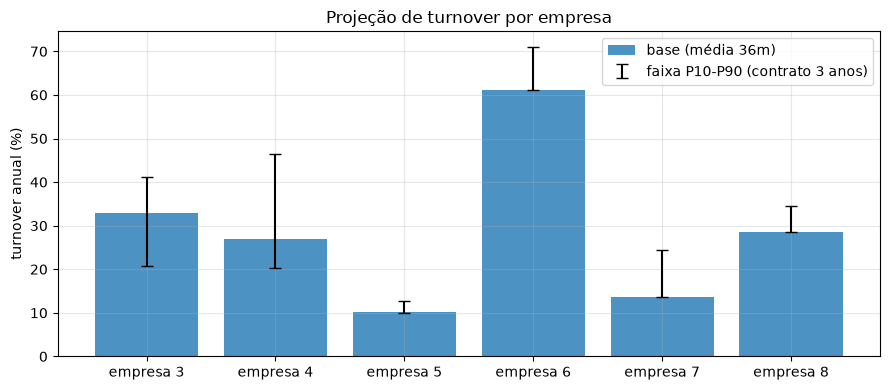

In [18]:
ok = proj.dropna(subset=['turnover_base_%'])
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ok)); ax.bar(x, ok['turnover_base_%'], color='C0', alpha=.8, label='base (média 36m)')
ax.errorbar(x, ok['turnover_base_%'], yerr=[ok['turnover_base_%'] - ok['contrato_baixo_%'], ok['contrato_alto_%'] - ok['turnover_base_%']],
            fmt='none', ecolor='k', capsize=4, label='faixa P10-P90 (contrato 3 anos)')
ax.set_xticks(x); ax.set_xticklabels([f'empresa {e}' for e in ok.index]); ax.set_ylabel('turnover anual (%)')
ax.set_title('Projeção de turnover por empresa'); ax.legend(); plt.tight_layout(); plt.show()

In [19]:
# salva o resultado
import os; os.makedirs('../resultados', exist_ok=True)
proj.round(2).to_csv('../resultados/trilha1_projecao.csv', encoding='utf-8-sig')
proj.round(1)[['ativos_set26', 'turnover_base_%', 'contrato_baixo_%', 'contrato_alto_%', 'confianca']]

,ativos_set26,turnover_base_%,contrato_baixo_%,contrato_alto_%,confianca
empresa,,,,,
1,0,NaN,NaN,NaN,NaN
3,113,32.8,20.7,41.1,média-baixa
4,7,27.0,20.4,46.4,baixa
5,2971,10.2,10.0,12.8,alta
6,797,61.1,61.1,71.0,baixa
7,45,13.6,13.6,24.5,média
8,1023,28.5,28.5,34.5,média-alta


## 6. Premissas e limitações

- **Taxa constante.** A projeção assume que o nível de rotatividade dos últimos 36 meses continua nos próximos 3 anos, sem tendência nem sazonalidade. O backtest mostra que isso funciona bem para as empresas 5 e 8, e mal para a 6.
- **Viés de subestimação.** Na maior parte do histórico e das empresas, o realizado ficou acima do projetado (a mediana da razão realizado/projetado é maior que 1 em todas as empresas com horizonte de 36 meses, 5, 6, 7 e 8, e na 3 com 24 meses). A faixa é assimétrica para cima, e **para precificação a faixa alta é a referência prudente** nas empresas de confiança baixa.
- **Empresa 6.** A rotatividade dela depende de ganhar ou perder contratos. A faixa é larga porque a incerteza é real, e mesmo o teto histórico é um valor extremo, não um cenário provável.
- **Saídas esperadas por ano** supõem headcount constante igual ao de set/2026 (admissões repõem saídas). Isso não é uma projeção de quadro.
- **Escala 6x1 → 5x2 (Trilha 3).** A projeção é do cenário atual. O efeito da mudança de escala na rotatividade precisa ser tratado na Trilha 3 e não está aqui.
- **Transferências entre empresas** (motivo de admissão 02) existem sobretudo nas empresas 3 e 7 e contam como admissão e rescisão. Não foram separadas.
- **Backtest com origens sobrepostas.** As origens consecutivas compartilham meses, então as faixas P10/P90 são aproximadas, e para horizontes longos há poucas observações independentes.